# PRAKTIKUM
## Nama : Oktova Yoga Praditia Samosir
## NIM  : 42324001
## Prodi: D3 Teknologi Informasi 

In [1]:
# in 1
import pandas as pd
import numpy as np
import re
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# tambahan (tidak ada di materi): resource nltk untuk tokenisasi dan lemmatization.
# kalau sebelumnya sudah pernah diunduh, baris ini aman dijalankan lagi.
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Oktovaaaaa\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Oktovaaaaa\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Oktovaaaaa\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [3]:
# in 2
# load dataset
file_path = "tmdb_5000_movies.csv"
df = pd.read_csv(file_path)

# hanya mengambil kolom message untuk klasterisasi
df = df.rename(columns={'Message': 'text'})

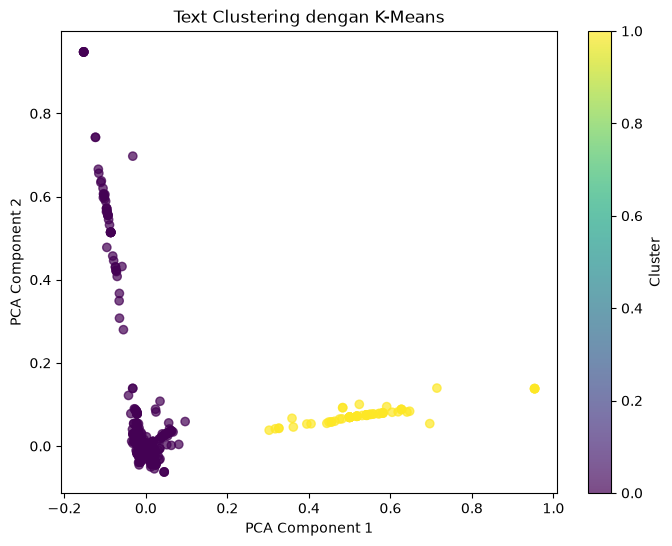

In [7]:
# in 3
# inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# fungsi preprocessing teks
def clean_text(text):
    text = text.lower()  # Lowercasing
    text = re.sub(r'\d+', '', text)  # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))  # Hapus tanda baca
    words = word_tokenize(text)  # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words]  # Lemmatization
    return ' '.join(words)

# terapkan preprocessing ke teks
df['clean_text'] = df['title'].apply(clean_text)

# konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')  # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])

# tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()